# ASCENT 4-130, Module 6 : Tests et validation des systèmes

**Jour 2, troisième séquence (2 heures).** Conception de scénarios de test pour agents intelligents, évaluation des performances et de la robustesse en conditions simulées, documentation et bonnes pratiques pour un déploiement réel.

**Le fil rouge.** Le robot de l'entrepôt sait naviguer. Avant de le mettre en service, il faut répondre à une autre question : dans quelles conditions peut-on lui faire confiance, et avec quel niveau de preuve ? Une démonstration réussie ne prouve rien : un agent autonome se valide sur des milliers d'exécutions, dans des conditions choisies pour le mettre en difficulté.

**Objectifs.**
- Concevoir une grille de scénarios de test (nominal, dégradé, limite).
- Lancer une campagne de simulations à grande échelle et mesurer des indicateurs.
- Quantifier l'incertitude statistique d'un taux de réussite.
- Écrire un test de non-régression avec des seuils d'acceptation.
- Rejouer un échec étape par étape pour en trouver la cause.
- Produire un rapport de validation.

**Durée indicative du TP (75 minutes).**

| Partie | Contenu | Durée |
|---|---|---|
| 1 | Concevoir les scénarios de test | 10 min |
| 2 | Campagne de simulations par lots | 15 min |
| 3 | Distributions et intervalles de confiance | 10 min |
| 4 | Seuils d'acceptation et non-régression | 10 min |
| 5 | Rejouer un échec | 10 min |
| 6 | Campagne fine sur des entrepôts aléatoires | 10 min |
| 7 | Rapport de validation et bonnes pratiques | 10 min |

Le notebook est livré exécuté : les sorties visibles servent de résultats de repli.

## Avant de commencer

**Ce qu'il faut connaître.** Chaque notion utilisée ici a sa leçon guidée dans le module 0 du site. Si l'une d'elles vous est nouvelle, commencez par là (8 à 10 minutes par leçon) :

- [Distribution des résultats et intervalle de confiance](https://martinobettucci.github.io/4-120/#/module/0/confiance)
- [Robustesse](https://martinobettucci.github.io/4-120/#/module/0/robustesse)
- [Reproductibilité et rejeu](https://martinobettucci.github.io/4-120/#/module/0/graine)

**Comment travailler dans ce notebook.** Pour chaque partie, suivez quatre temps :

1. **Lire** l'explication qui précède le code.
2. **Prédire** ce que la cellule va afficher, avant de l'exécuter. Notez votre prédiction, même approximative.
3. **Exécuter**, puis comparer le résultat à votre prédiction. Un écart est une information : cherchez d'où il vient.
4. **Modifier** une valeur de la cellule `PARAMETRES`, relancer, et expliquer en une phrase ce qui a changé.

**Dans les exercices**, l'aide est graduée : essayez d'abord seul, relisez ensuite l'exemple qui précède, et n'ouvrez la « Solution possible » qu'après un essai. Comparer sa propre tentative à la solution apprend davantage que la lire directement.

In [1]:
# Installation automatique (Colab ou poste sans le paquet). Sans effet si tout est déjà installé.
import importlib.util, subprocess, sys
if importlib.util.find_spec("ascent_agents") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ascent-agents[complet] @ https://martinobettucci.github.io/4-120/dist/ascent_agents-1.0.0-py3-none-any.whl"])

In [2]:
import json
import math
import platform
import time
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

import ascent_agents
from ascent_agents import creer_scenario, detecter_appareil, fixer_graines, simuler
from ascent_agents.agents import AgentDeliberatif, AgentHybride, AgentReactif, a_etoile
from ascent_agents.incertitude import AgentRobuste
from ascent_agents.lot import SimulationLot
from ascent_agents.monde import Evenement, entrepot_aleatoire
from ascent_agents.visualisation import BLEU, GRIS, JAUNE, NOIR, ROUGE, VERT, dessiner_monde, dessiner_trace, style

APPAREIL = detecter_appareil()
GRAINE = fixer_graines(4130)
style()
RESULTATS = Path("resultats")
RESULTATS.mkdir(exist_ok=True)

Aucun GPU CUDA detecte : repli sur CPU (tous les notebooks restent executables).
PyTorch 2.15.0+cpu


## Partie 1. Concevoir les scénarios de test

Un plan de test pour un agent autonome décrit trois choses :

1. **Le système testé.** Ici, une politique de navigation : descendre le champ de distance vers l'objectif, en évitant les cellules que la perception signale comme occupées.
2. **Les conditions d'essai.** On ne teste pas seulement le cas prévu. On distingue le domaine **nominal** (conditions attendues en service), le domaine **dégradé** (perturbations plausibles) et le domaine **limite** (au delà de ce que le système est censé supporter, pour savoir où il casse).
3. **Les critères d'acceptation.** Des seuils chiffrés, fixés avant la campagne.

Trois perturbations sont disponibles dans le simulateur par lots :

| Paramètre | Ce qu'il représente |
|---|---|
| `glissement` | probabilité qu'un déplacement ne s'exécute pas (sol glissant, roue bloquée) |
| `rate_perception` | probabilité de ne pas voir un obstacle mobile voisin (capteur sale, angle mort) |
| `n_obstacles` | nombre d'obstacles mobiles qui errent dans l'entrepôt (trafic) |

La mission est limitée à `max_etapes` étapes : un robot qui arrive trop tard a échoué. Le plus court chemin fait 26 pas.

In [3]:
# PARAMÈTRES MODIFIABLES : grille de niveaux de perturbation.
NIVEAUX = [
    {"nom": "nominal", "domaine": "nominal", "glissement": 0.00, "rate_perception": 0.00, "n_obstacles": 0},
    {"nom": "léger",   "domaine": "nominal", "glissement": 0.05, "rate_perception": 0.05, "n_obstacles": 2},
    {"nom": "dégradé", "domaine": "dégradé", "glissement": 0.15, "rate_perception": 0.20, "n_obstacles": 6},
    {"nom": "sévère",  "domaine": "dégradé", "glissement": 0.30, "rate_perception": 0.40, "n_obstacles": 10},
    {"nom": "limite",  "domaine": "limite",  "glissement": 0.45, "rate_perception": 0.60, "n_obstacles": 16},
]
PARAMETRES_CAMPAGNE = {"lot": 4000, "max_etapes": 45, "graine": GRAINE}

# Critères d'acceptation, fixés AVANT de lancer la campagne.
SEUILS = {
    "nominal": {"succès min": 0.98, "collisions max": 0.10},
    "dégradé": {"succès min": 0.60, "collisions max": 2.50},
    "limite":  {},   # pas d'exigence : on observe seulement où le système casse
}
monde = creer_scenario("entrepot", chariots=False)
pd.DataFrame(NIVEAUX).set_index("nom")

,domaine,glissement,rate_perception,n_obstacles
nom,,,,
nominal,nominal,0.00,0.00,0
léger,nominal,0.05,0.05,2
dégradé,dégradé,0.15,0.20,6
sévère,dégradé,0.30,0.40,10
limite,limite,0.45,0.60,16


## Partie 2. Campagne de simulations par lots

`SimulationLot` fait évoluer des milliers d'environnements en même temps sous forme de tenseurs PyTorch : positions des robots (lot × 2), positions des obstacles (lot × obstacles × 2). Chaque environnement tire ses propres aléas. C'est le cas d'usage où le GPU apporte un gain réel ; sur CPU, le même code fonctionne avec un débit plus faible.

Deux versions de la politique sont comparées :

- **avant correction** (`prudence=False`) : le robot descend le champ de distance sans tenir compte des obstacles mobiles ;
- **après correction** (`prudence=True`) : il évite les cellules où il perçoit un obstacle.

L'intervalle de confiance du taux de réussite est calculé par la méthode de Wilson, fiable même pour des taux proches de 0 ou de 1.

In [4]:
def wilson(succes, n, z=1.96):
    """Intervalle de confiance de Wilson à 95 % pour une proportion observée succes / n."""
    p = succes / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    demi = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return max(0.0, centre - demi), min(1.0, centre + demi)


def lancer_niveau(niveau, prudence, lot=None, max_etapes=None, graine=None, enregistrer=0):
    """Exécute un niveau de la grille et retourne (indicateurs, résultat brut)."""
    lot = lot or PARAMETRES_CAMPAGNE["lot"]
    brut = SimulationLot(monde, lot=lot, n_obstacles=niveau["n_obstacles"], glissement=niveau["glissement"],
                         rate_perception=niveau["rate_perception"], prudence=prudence, appareil=APPAREIL,
                         graine=graine or PARAMETRES_CAMPAGNE["graine"]).executer(max_etapes=max_etapes or PARAMETRES_CAMPAGNE["max_etapes"], enregistrer=enregistrer)
    bas, haut = wilson(int(brut["succes"].sum()), lot)
    reussies = brut["etapes"][brut["succes"]]
    indicateurs = {
        "niveau": niveau["nom"], "domaine": niveau["domaine"], "version": "après correction" if prudence else "avant correction",
        "succès": brut["taux_succes"], "IC bas": bas, "IC haut": haut,
        "mission sûre": float((brut["succes"] & (brut["collisions"] == 0)).mean()),   # arrivée à temps ET sans aucun choc
        "collisions": brut["collisions_moyennes"],
        "étapes (médiane)": float(np.median(reussies)) if len(reussies) else np.nan,
        "étapes (p95)": float(np.percentile(reussies, 95)) if len(reussies) else np.nan,
        "pas par seconde": brut["pas_par_seconde"],
    }
    return indicateurs, brut


debut = time.perf_counter()
bruts, lignes = {}, []
for niveau in NIVEAUX:
    for prudence in (False, True):
        indicateurs, brut = lancer_niveau(niveau, prudence)
        lignes.append(indicateurs)
        bruts[niveau["nom"], indicateurs["version"]] = brut
campagne = pd.DataFrame(lignes)
total = len(NIVEAUX) * 2 * PARAMETRES_CAMPAGNE["lot"]
print(f"{total} missions simulées sur {APPAREIL} en {time.perf_counter() - debut:.1f} s")
campagne.round(3)

40000 missions simulées sur cpu en 1.4 s


,niveau,domaine,version,succès,IC bas,IC haut,mission sûre,collisions,étapes (médiane),étapes (p95),pas par seconde
0,nominal,nominal,avant correction,1.000,0.999,1.000,1.000,0.000,26.0,26.0,3400767
1,nominal,nominal,après correction,1.000,0.999,1.000,1.000,0.000,26.0,26.0,3788426
2,léger,nominal,avant correction,0.984,0.980,0.987,0.705,1.722,28.0,37.0,1207508
3,léger,nominal,après correction,0.992,0.988,0.994,0.949,0.058,28.0,34.0,1392832
4,dégradé,dégradé,avant correction,0.880,0.870,0.890,0.345,4.536,33.0,43.0,1028622
5,dégradé,dégradé,après correction,0.938,0.930,0.945,0.652,0.659,32.0,41.0,978858
6,sévère,dégradé,avant correction,0.531,0.516,0.546,0.172,5.925,39.0,45.0,876677
7,sévère,dégradé,après correction,0.665,0.650,0.679,0.327,1.862,39.0,45.0,818829
8,limite,limite,avant correction,0.065,0.058,0.073,0.026,6.133,43.0,45.0,712524
9,limite,limite,après correction,0.096,0.087,0.106,0.044,3.083,43.0,45.0,717157


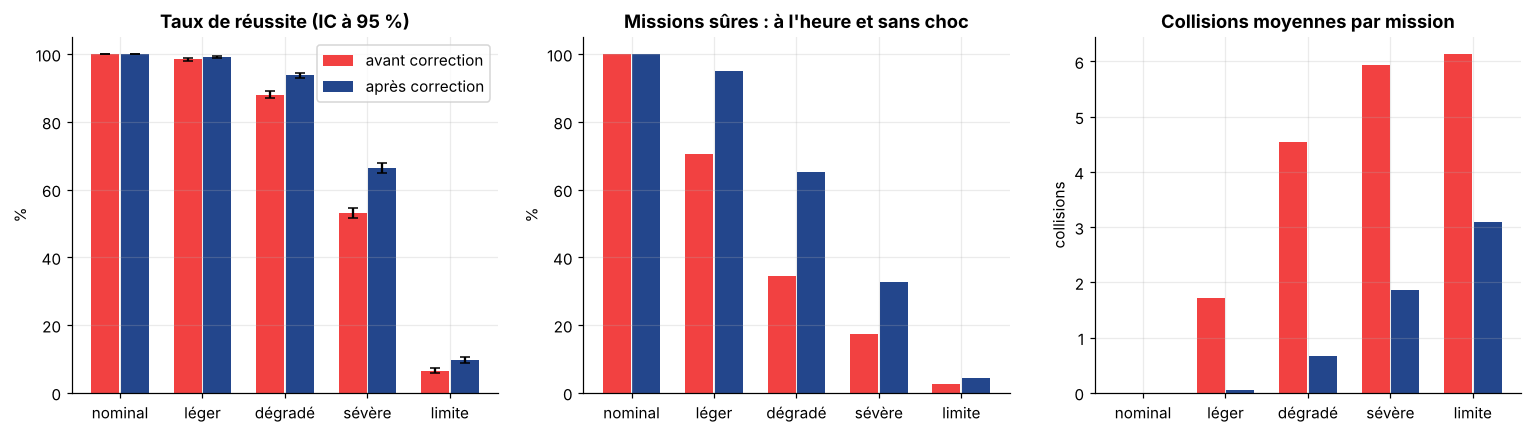

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
noms = [n["nom"] for n in NIVEAUX]
x = np.arange(len(noms))
for k, (version, couleur) in enumerate((("avant correction", ROUGE), ("après correction", BLEU))):
    d = campagne[campagne["version"] == version].set_index("niveau").loc[noms]
    decal = (k - 0.5) * 0.36
    axes[0].bar(x + decal, 100 * d["succès"], 0.34, color=couleur, label=version,
                yerr=np.clip([100 * (d["succès"] - d["IC bas"]), 100 * (d["IC haut"] - d["succès"])], 0, None), capsize=3)
    axes[1].bar(x + decal, 100 * d["mission sûre"], 0.34, color=couleur, label=version)
    axes[2].bar(x + decal, d["collisions"], 0.34, color=couleur, label=version)
for ax, titre, unite in zip(axes, ("Taux de réussite (IC à 95 %)", "Missions sûres : à l'heure et sans choc", "Collisions moyennes par mission"), ("%", "%", "collisions")):
    ax.set_xticks(x, noms)
    ax.set_title(titre)
    ax.set_ylabel(unite)
axes[0].legend()
plt.show()

**Lecture.** En conditions nominales strictes, les deux versions sont parfaites et indiscernables : un test nominal seul ne dit rien de la robustesse. Dès le niveau « léger », la version d'avant correction heurte des obstacles dans une part notable des missions. Le taux de réussite seul masque ce défaut, puisque le robot finit par arriver. D'où deux règles : **plusieurs indicateurs**, et des **niveaux de perturbation croissants** jusqu'à la rupture.

### Débit de simulation : où le GPU sert

La cellule suivante mesure le nombre de pas de simulation par seconde selon la taille du lot. Avec CUDA, la comparaison CPU / GPU est affichée.

In [6]:
niveau_ref = NIVEAUX[2]
lignes = []
for lot in (100, 1000, 10000):
    for appareil in dict.fromkeys(["cpu", str(APPAREIL)]):
        r = SimulationLot(monde, lot=lot, n_obstacles=niveau_ref["n_obstacles"], glissement=niveau_ref["glissement"],
                          rate_perception=niveau_ref["rate_perception"], appareil=appareil).executer(max_etapes=45)
        lignes.append({"lot": lot, "appareil": appareil, "durée (s)": r["duree_s"], "pas par seconde": r["pas_par_seconde"]})
debit = pd.DataFrame(lignes)
if str(APPAREIL) == "cpu":
    print("Pas de GPU détecté : mesures sur CPU uniquement. Le débit augmente avec la taille du lot, car le coût fixe de chaque opération est partagé.")
debit

Pas de GPU détecté : mesures sur CPU uniquement. Le débit augmente avec la taille du lot, car le coût fixe de chaque opération est partagé.


,lot,appareil,durée (s),pas par seconde
0,100,cpu,0.0085,402851
1,1000,cpu,0.0359,939923
2,10000,cpu,0.3469,967390


### Exercice 1. Concevoir votre niveau de perturbation

Définissez un niveau qui isole **une seule** perturbation (par exemple un trafic dense avec une perception parfaite et sans glissement). Avant d'exécuter, notez votre prédiction : la correction sera-t-elle plus ou moins utile que dans le niveau « dégradé » ?

In [7]:
# À VOUS : définissez votre niveau.
MON_NIVEAU = {"nom": "trafic dense", "domaine": "dégradé", "glissement": 0.0, "rate_perception": 0.0, "n_obstacles": 12}

pd.DataFrame([lancer_niveau(MON_NIVEAU, prudence)[0] for prudence in (False, True)]).round(3)

,niveau,domaine,version,succès,IC bas,IC haut,mission sûre,collisions,étapes (médiane),étapes (p95),pas par seconde
0,trafic dense,dégradé,avant correction,0.827,0.815,0.839,0.119,9.907,32.0,43.0,607194
1,trafic dense,dégradé,après correction,0.927,0.918,0.934,0.926,0.000,29.0,42.0,587542


**Solution possible.** On isole chaque perturbation tour à tour, à un niveau élevé.

In [8]:
isoles = [
    {"nom": "glissement seul", "domaine": "dégradé", "glissement": 0.35, "rate_perception": 0.0, "n_obstacles": 0},
    {"nom": "trafic seul", "domaine": "dégradé", "glissement": 0.0, "rate_perception": 0.0, "n_obstacles": 12},
    {"nom": "trafic et perception", "domaine": "dégradé", "glissement": 0.0, "rate_perception": 0.5, "n_obstacles": 12},
]
tableau = pd.DataFrame([lancer_niveau(n, p)[0] for n in isoles for p in (False, True)])
print("Le glissement seul ne cause aucune collision : il ralentit le robot et fait manquer l'échéance. La correction n'y change rien.")
print("Le trafic seul est presque entièrement traité par la correction, tant que la perception est fiable.")
print("Avec une perception défaillante, la correction perd son efficacité : elle ne peut pas éviter ce qu'elle ne voit pas.")
tableau[["niveau", "version", "succès", "mission sûre", "collisions", "étapes (médiane)"]].round(3)

Le glissement seul ne cause aucune collision : il ralentit le robot et fait manquer l'échéance. La correction n'y change rien.
Le trafic seul est presque entièrement traité par la correction, tant que la perception est fiable.
Avec une perception défaillante, la correction perd son efficacité : elle ne peut pas éviter ce qu'elle ne voit pas.


,niveau,version,succès,mission sûre,collisions,étapes (médiane)
0,glissement seul,avant correction,0.874,0.874,0.000,39.0
1,glissement seul,après correction,0.874,0.874,0.000,39.0
2,trafic seul,avant correction,0.827,0.119,9.907,32.0
3,trafic seul,après correction,0.927,0.926,0.000,29.0
4,trafic et perception,avant correction,0.827,0.119,9.907,32.0
5,trafic et perception,après correction,0.916,0.222,3.885,30.0


## Partie 3. Distributions et intervalles de confiance

Une moyenne résume mal un comportement. Deux politiques de même durée médiane peuvent avoir des queues de distribution très différentes, et ce sont les cas rares qui causent les incidents.

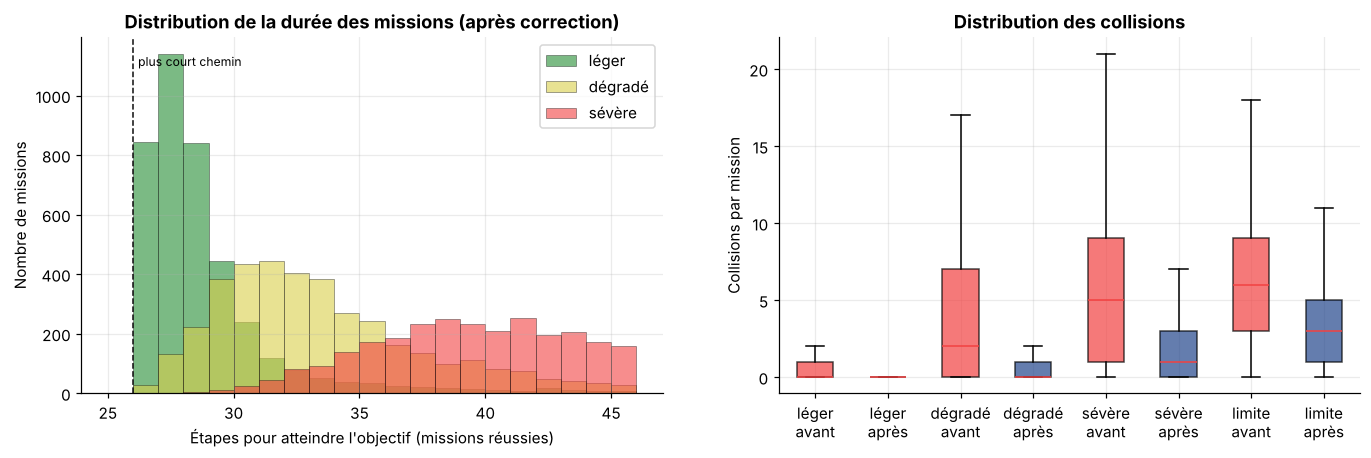

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
bords = np.arange(25, PARAMETRES_CAMPAGNE["max_etapes"] + 2)
for nom, couleur in (("léger", VERT), ("dégradé", JAUNE), ("sévère", ROUGE)):
    brut = bruts[nom, "après correction"]
    axes[0].hist(brut["etapes"][brut["succes"]], bins=bords, color=couleur, alpha=0.6, label=nom, edgecolor=NOIR, lw=0.4)
axes[0].axvline(26, color=NOIR, ls="--", lw=1)
axes[0].text(26.2, axes[0].get_ylim()[1] * 0.92, "plus court chemin", fontsize=8)
axes[0].set_xlabel("Étapes pour atteindre l'objectif (missions réussies)")
axes[0].set_ylabel("Nombre de missions")
axes[0].set_title("Distribution de la durée des missions (après correction)")
axes[0].legend()
donnees, etiquettes, couleurs = [], [], []
for nom in noms[1:]:
    for version, couleur in (("avant correction", ROUGE), ("après correction", BLEU)):
        donnees.append(bruts[nom, version]["collisions"])
        etiquettes.append(f"{nom}\n{version.split()[0]}")
        couleurs.append(couleur)
boites = axes[1].boxplot(donnees, patch_artist=True, showfliers=False)
axes[1].set_xticks(range(1, len(etiquettes) + 1), etiquettes)
for b, c in zip(boites["boxes"], couleurs):
    b.set_facecolor(c)
    b.set_alpha(0.7)
axes[1].set_ylabel("Collisions par mission")
axes[1].set_title("Distribution des collisions")
plt.show()

### Combien de simulations faut-il ?

Un taux de réussite mesuré sur n essais est une estimation. L'intervalle de confiance en donne la précision : sa largeur diminue comme 1 / √n. Pour diviser l'incertitude par 2, il faut 4 fois plus d'essais.

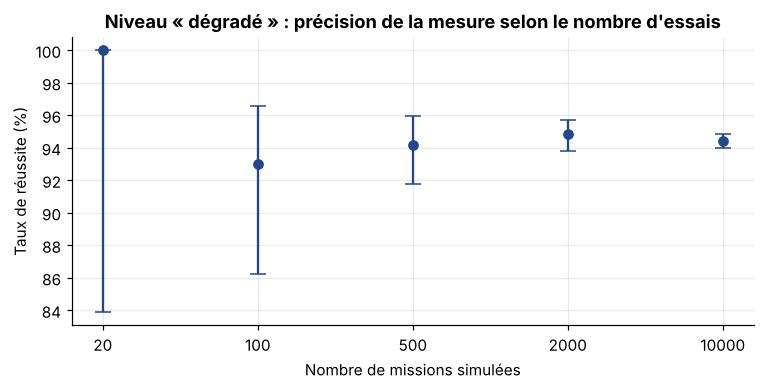

,essais,succès mesuré (%),IC bas (%),IC haut (%),largeur (points)
0,20,100.0,83.9,100.0,16.1
1,100,93.0,86.3,96.6,10.3
2,500,94.2,91.8,95.9,4.1
3,2000,94.8,93.8,95.7,1.9
4,10000,94.4,94.0,94.9,0.9


In [10]:
niveau = NIVEAUX[2]
lignes = []
for lot in (20, 100, 500, 2000, 10000):
    r = SimulationLot(monde, lot=lot, n_obstacles=niveau["n_obstacles"], glissement=niveau["glissement"], rate_perception=niveau["rate_perception"],
                      appareil=APPAREIL, graine=GRAINE).executer(max_etapes=45)
    bas, haut = wilson(int(r["succes"].sum()), lot)
    lignes.append({"essais": lot, "succès mesuré (%)": 100 * r["taux_succes"], "IC bas (%)": 100 * bas, "IC haut (%)": 100 * haut, "largeur (points)": 100 * (haut - bas)})
precision = pd.DataFrame(lignes)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.errorbar(range(len(precision)), precision["succès mesuré (%)"], yerr=np.clip([precision["succès mesuré (%)"] - precision["IC bas (%)"], precision["IC haut (%)"] - precision["succès mesuré (%)"]], 0, None),
            fmt="o", color=BLEU, capsize=5)
ax.set_xticks(range(len(precision)), precision["essais"])
ax.set_xlabel("Nombre de missions simulées")
ax.set_ylabel("Taux de réussite (%)")
ax.set_title("Niveau « dégradé » : précision de la mesure selon le nombre d'essais")
plt.show()
precision.round(1)

Avec 20 essais, l'intervalle couvre plusieurs dizaines de points : on ne peut pas distinguer un système correct d'un système médiocre. C'est la raison d'être de la simulation à grande échelle.

### Exercice 2. Dimensionner une campagne

L'exigence est la suivante : démontrer, au niveau « léger », que le taux de réussite dépasse 98 %, c'est à dire que la **borne basse** de l'intervalle de confiance est au dessus de 98 %. Combien de missions faut-il simuler ? Modifiez `ESSAIS` jusqu'à obtenir la démonstration.

In [11]:
# À VOUS : choisissez le nombre de missions.
ESSAIS = 200

indicateurs, _ = lancer_niveau(NIVEAUX[1], prudence=True, lot=ESSAIS)
print(f"{ESSAIS} missions : succès {100 * indicateurs['succès']:.2f} %, IC à 95 % [{100 * indicateurs['IC bas']:.2f} ; {100 * indicateurs['IC haut']:.2f}]")
print("Exigence démontrée" if indicateurs["IC bas"] > 0.98 else "Exigence non démontrée : la borne basse est sous 98 %")

200 missions : succès 99.50 %, IC à 95 % [97.22 ; 99.91]
Exigence non démontrée : la borne basse est sous 98 %


**Solution possible.** On augmente le nombre d'essais jusqu'à ce que la borne basse franchisse le seuil. On peut aussi estimer le besoin par le calcul : pour un taux réel p et une marge m entre p et le seuil, il faut au moins n ≈ 1,96² × p × (1 - p) / m² essais.

In [12]:
for essais in (200, 1000, 4000, 16000):
    ind, _ = lancer_niveau(NIVEAUX[1], prudence=True, lot=essais)
    verdict = "démontrée" if ind["IC bas"] > 0.98 else "non démontrée"
    print(f"{essais:6d} missions : succès {100 * ind['succès']:.2f} %, borne basse {100 * ind['IC bas']:.2f} %, exigence {verdict}")
p, m = ind["succès"], ind["succès"] - 0.98
if m > 0:
    print(f"Estimation par le calcul : au moins {1.96 ** 2 * p * (1 - p) / m ** 2:.0f} missions pour une marge de {100 * m:.2f} point(s).")
    print("Ce minimum suppose que la mesure tombe exactement sur le taux réel. Comme elle fluctue d'une campagne à l'autre, on prévoit plusieurs fois ce nombre.")
print("Plus le taux réel est proche du seuil, plus la démonstration coûte cher. Si le taux réel est sous le seuil, aucune quantité d'essais ne suffira.")

   200 missions : succès 99.50 %, borne basse 97.22 %, exigence non démontrée
  1000 missions : succès 98.70 %, borne basse 97.79 %, exigence non démontrée
  4000 missions : succès 99.15 %, borne basse 98.81 %, exigence démontrée


 16000 missions : succès 99.18 %, borne basse 99.02 %, exigence démontrée
Estimation par le calcul : au moins 228 missions pour une marge de 1.18 point(s).
Ce minimum suppose que la mesure tombe exactement sur le taux réel. Comme elle fluctue d'une campagne à l'autre, on prévoit plusieurs fois ce nombre.
Plus le taux réel est proche du seuil, plus la démonstration coûte cher. Si le taux réel est sous le seuil, aucune quantité d'essais ne suffira.


## Partie 4. Seuils d'acceptation et test de non-régression

Un test de non-régression rejoue la même campagne à chaque modification du système et compare les indicateurs aux seuils fixés à l'avance. Le verdict est automatique : conforme ou non conforme. La graine fixée rend la campagne reproductible : un écart vient du système, pas du hasard.

Règle de décision prudente : pour le taux de réussite, on compare la **borne basse** de l'intervalle de confiance au seuil, et non la valeur mesurée.

In [13]:
def verifier(campagne, seuils):
    """Compare chaque ligne de la campagne aux seuils de son domaine. Retourne un tableau de verdicts."""
    lignes = []
    for _, r in campagne.iterrows():
        s = seuils.get(r["domaine"], {})
        ecarts = []
        if "succès min" in s and r["IC bas"] < s["succès min"]:
            ecarts.append(f"succès (borne basse {100 * r['IC bas']:.1f} %) sous le seuil de {100 * s['succès min']:.0f} %")
        if "collisions max" in s and r["collisions"] > s["collisions max"]:
            ecarts.append(f"collisions ({r['collisions']:.2f}) au dessus du seuil de {s['collisions max']}")
        verdict = "observation" if not s else ("conforme" if not ecarts else "NON CONFORME")
        lignes.append({"niveau": r["niveau"], "domaine": r["domaine"], "version": r["version"], "verdict": verdict, "écarts": " ; ".join(ecarts)})
    return pd.DataFrame(lignes)


verdicts = verifier(campagne, SEUILS)
pd.set_option("display.max_colwidth", 120)
for version in ("avant correction", "après correction"):
    v = verdicts[verdicts["version"] == version]
    exiges = v[v["verdict"] != "observation"]
    print(f"{version} : {(exiges['verdict'] == 'conforme').sum()} niveau(x) conforme(s) sur {len(exiges)}")
verdicts

avant correction : 1 niveau(x) conforme(s) sur 4
après correction : 4 niveau(x) conforme(s) sur 4


,niveau,domaine,version,verdict,écarts
0,nominal,nominal,avant correction,conforme,
1,nominal,nominal,après correction,conforme,
2,léger,nominal,avant correction,NON CONFORME,succès (borne basse 98.0 %) sous le seuil de 98 % ; collisions (1.72) au dessus du seuil de 0.1
3,léger,nominal,après correction,conforme,
4,dégradé,dégradé,avant correction,NON CONFORME,collisions (4.54) au dessus du seuil de 2.5
5,dégradé,dégradé,après correction,conforme,
6,sévère,dégradé,avant correction,NON CONFORME,succès (borne basse 51.6 %) sous le seuil de 60 % ; collisions (5.93) au dessus du seuil de 2.5
7,sévère,dégradé,après correction,conforme,
8,limite,limite,avant correction,observation,
9,limite,limite,après correction,observation,


La version d'avant correction échoue au contrôle, y compris dans le domaine nominal (niveau « léger »). La version corrigée satisfait les exigences des domaines nominal et dégradé. Le niveau « limite » n'a pas de seuil : il sert à documenter le point de rupture.

### Exercice 3. Trouver le point de rupture

Jusqu'à quel taux de glissement la version corrigée tient-elle l'exigence du domaine dégradé (borne basse du succès au dessus de 60 %) ? Balayez le glissement, les autres paramètres restant ceux du niveau « dégradé ».

In [14]:
# À VOUS : choisissez les valeurs de glissement à tester.
GLISSEMENTS = [0.15, 0.40]

for g in GLISSEMENTS:
    ind, _ = lancer_niveau(dict(NIVEAUX[2], glissement=g), prudence=True)
    print(f"glissement {g:.2f} : succès {100 * ind['succès']:.1f} %, borne basse {100 * ind['IC bas']:.1f} %")

glissement 0.15 : succès 93.8 %, borne basse 93.0 %


glissement 0.40 : succès 47.5 %, borne basse 46.0 %


**Solution possible.**

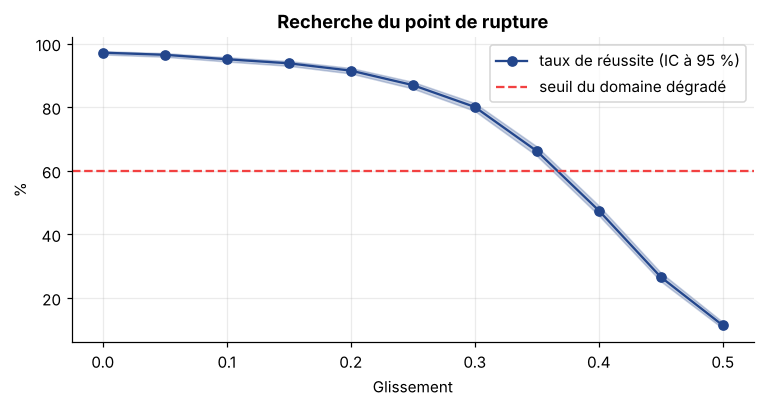

L'exigence est tenue jusqu'à un glissement d'environ 0.35. La chute est brutale : avec une échéance de 45 étapes pour 26 pas utiles,
le robot dispose d'une marge fixe, et le glissement la consomme. Le point de rupture dépend donc autant de l'échéance que de la politique.


In [15]:
glissements = np.arange(0.0, 0.51, 0.05)
courbe = pd.DataFrame([lancer_niveau(dict(NIVEAUX[2], glissement=float(g)), prudence=True)[0] for g in glissements])
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.fill_between(glissements, 100 * courbe["IC bas"], 100 * courbe["IC haut"], color=BLEU, alpha=0.25)
ax.plot(glissements, 100 * courbe["succès"], "o-", color=BLEU, label="taux de réussite (IC à 95 %)")
ax.axhline(60, color=ROUGE, ls="--", label="seuil du domaine dégradé")
ax.set_xlabel("Glissement")
ax.set_ylabel("%")
ax.set_title("Recherche du point de rupture")
ax.legend()
plt.show()
tenus = glissements[(courbe["IC bas"] >= 0.60).values]
print(f"L'exigence est tenue jusqu'à un glissement d'environ {tenus.max():.2f}. La chute est brutale : avec une échéance de 45 étapes pour 26 pas utiles,")
print("le robot dispose d'une marge fixe, et le glissement la consomme. Le point de rupture dépend donc autant de l'échéance que de la politique.")

## Partie 5. Rejouer un échec

Un taux ne dit pas **pourquoi** le système échoue. L'option `enregistrer` conserve l'historique complet des premiers environnements du lot. On y cherche une mission avec collision et on la rejoue étape par étape. La campagne étant reproductible (graine fixée), l'échec se reproduit à l'identique à chaque exécution.

77 missions avec collision parmi les 200 enregistrées
Mission n° 103 : 7 collision(s), arrivée à temps : False, étapes suspectes : [17, 18, 20, 21, 22, 23, 24, 25]


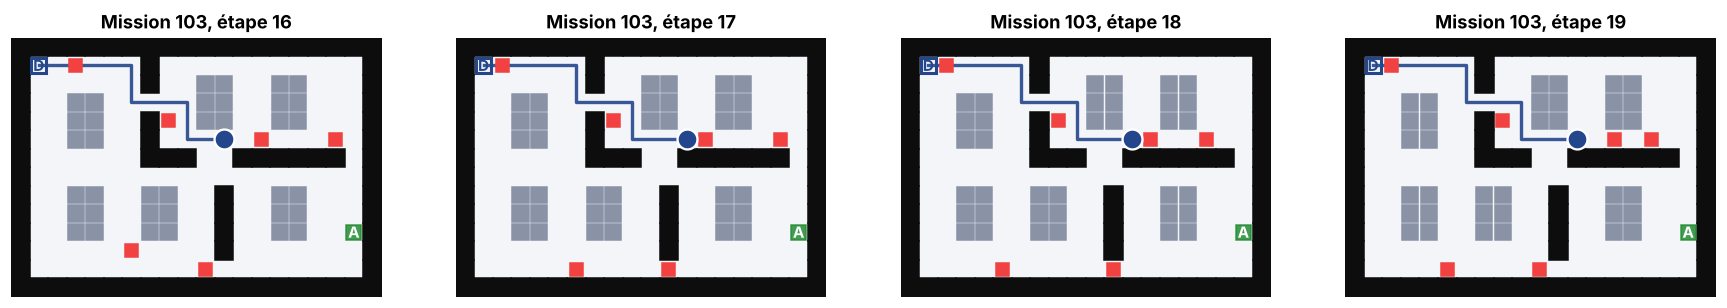

In [16]:
N_ENREGISTRES = 200
_, brut = lancer_niveau(NIVEAUX[2], prudence=True, lot=2000, enregistrer=N_ENREGISTRES)
historique = brut["historique"]                       # liste de (positions des robots, positions des obstacles)
fautifs = [i for i in range(N_ENREGISTRES) if brut["collisions"][i] > 0]
print(f"{len(fautifs)} missions avec collision parmi les {N_ENREGISTRES} enregistrées")


def instants_suspects(i):
    """Étapes où le robot i n'a pas bougé alors qu'un obstacle occupait une cellule voisine."""
    suspects = []
    for t in range(len(historique) - 1):
        robot, suivant = historique[t][0][i], historique[t + 1][0][i]
        voisins = np.abs(historique[t][1][i] - robot).sum(1) == 1
        if (robot == suivant).all() and voisins.any() and not (robot == monde.objectif).all():
            suspects.append(t)
    return suspects


cas = max(fautifs, key=lambda i: brut["collisions"][i])
suspects = instants_suspects(cas)
print(f"Mission n° {cas} : {brut['collisions'][cas]} collision(s), arrivée à temps : {bool(brut['succes'][cas])}, étapes suspectes : {suspects[:8]}")

t0 = max(suspects[0] - 1, 0) if suspects else 0
fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
for ax, t in zip(axes, range(t0, t0 + 4)):
    t = min(t, len(historique) - 1)
    trajet = [tuple(h[0][cas]) for h in historique[: t + 1]]
    dessiner_monde(monde, ax, trajectoires={"robot": trajet}, robot=tuple(historique[t][0][cas]), obstacles=[tuple(o) for o in historique[t][1][cas]], titre=f"Mission {cas}, étape {t}")
    ax.get_legend().remove()
plt.show()

Le rejeu montre le mécanisme : un obstacle mobile se trouve sur une cellule voisine, la perception le manque (20 % de chances à ce niveau) et le robot avance dessus. La correction ne protège que de ce qui est perçu. L'analyse oriente la suite : améliorer la perception (fusion de plusieurs lectures, vitesse réduite près du trafic) plutôt que la planification.

## Partie 6. Campagne fine sur des entrepôts aléatoires

La simulation par lots évalue vite une politique simple sur une carte fixe. Pour les agents complets du paquet (réactif, délibératif, hybride, robuste), on utilise la boucle `simuler`, plus lente mais qui produit une trace détaillée, sur des entrepôts **générés aléatoirement** : tester sur des cartes jamais vues évite de valider un agent ajusté à une seule carte. Dans chaque entrepôt, une palette imprévue est déposée sur le plus court chemin.

In [17]:
# PARAMÈTRES MODIFIABLES : campagne fine.
PARAMETRES_FINE = {"entrepots": 30, "densite": 0.14, "glissement": 0.1, "bruit_lidar": 0.3, "max_etapes": 120}
AGENTS = {
    "réactif": AgentReactif,
    "délibératif": AgentDeliberatif,
    "hybride": AgentHybride,
    "robuste": lambda: AgentRobuste(glissement=0.1, bruit_lidar=0.5),
}


def fabriquer(graine):
    """Entrepôt aléatoire avec une palette déposée à l'étape 2 au milieu du plus court chemin."""
    m = entrepot_aleatoire(graine, densite=PARAMETRES_FINE["densite"], glissement=PARAMETRES_FINE["glissement"], bruit_lidar=PARAMETRES_FINE["bruit_lidar"])
    plan, _ = a_etoile(m, m.depart, m.objectif)
    m.evenements = [Evenement(2, plan[len(plan) // 2])]
    return m


lignes, traces = [], {}
debut = time.perf_counter()
for graine in range(PARAMETRES_FINE["entrepots"]):
    for nom, fabrique in AGENTS.items():
        trace = simuler(fabriquer(graine), fabrique(), max_etapes=PARAMETRES_FINE["max_etapes"], identifiant=f"m6-{nom}-{graine}", module=6,
                        titre=f"Agent {nom}, entrepôt aléatoire {graine}")
        traces[nom, graine] = trace
        b = trace.bilan
        lignes.append({"entrepôt": graine, "agent": nom, "succès": b["succes"], "étapes": b["etapes"], "collisions": b["collisions"],
                       "décision moyenne (ms)": b["temps_decision_moyen_ms"], "décision max (ms)": b["temps_decision_max_ms"],
                       "plus court chemin": len(a_etoile(trace_monde := fabriquer(graine), trace_monde.depart, trace_monde.objectif)[0]) - 1})
fine = pd.DataFrame(lignes)
fine["allongement"] = fine["étapes"] / fine["plus court chemin"]
print(f"{len(fine)} exécutions en {time.perf_counter() - debut:.1f} s (boucle séquentielle sur CPU : le GPU n'intervient pas ici)")


def resumer(groupe):
    reussies = groupe[groupe["succès"]]
    bas, haut = wilson(int(groupe["succès"].sum()), len(groupe))
    return pd.Series({
        "succès (%)": 100 * groupe["succès"].mean(), "IC à 95 % (%)": f"[{100 * bas:.0f} ; {100 * haut:.0f}]",
        "missions sans collision (%)": 100 * (groupe["collisions"] == 0).mean(), "collisions (moyenne)": groupe["collisions"].mean(),
        "allongement médian": reussies["allongement"].median() if len(reussies) else np.nan,
        "décision moyenne (ms)": groupe["décision moyenne (ms)"].mean(), "décision max (ms)": groupe["décision max (ms)"].max(),
    })


synthese = fine.groupby("agent", sort=False)[fine.columns.tolist()].apply(resumer)
synthese.round(3)

120 exécutions en 1.1 s (boucle séquentielle sur CPU : le GPU n'intervient pas ici)


,succès (%),IC à 95 % (%),missions sans collision (%),collisions (moyenne),allongement médian,décision moyenne (ms),décision max (ms)
agent,,,,,,,
réactif,83.333,[66 ; 93],63.333,1.533,1.107,0.001,0.124
délibératif,0.000,[0 ; 11],3.333,8.067,NaN,0.001,0.039
hybride,100.000,[89 ; 100],96.667,0.033,1.179,0.015,0.339
robuste,100.000,[89 ; 100],96.667,0.033,1.179,0.147,0.721


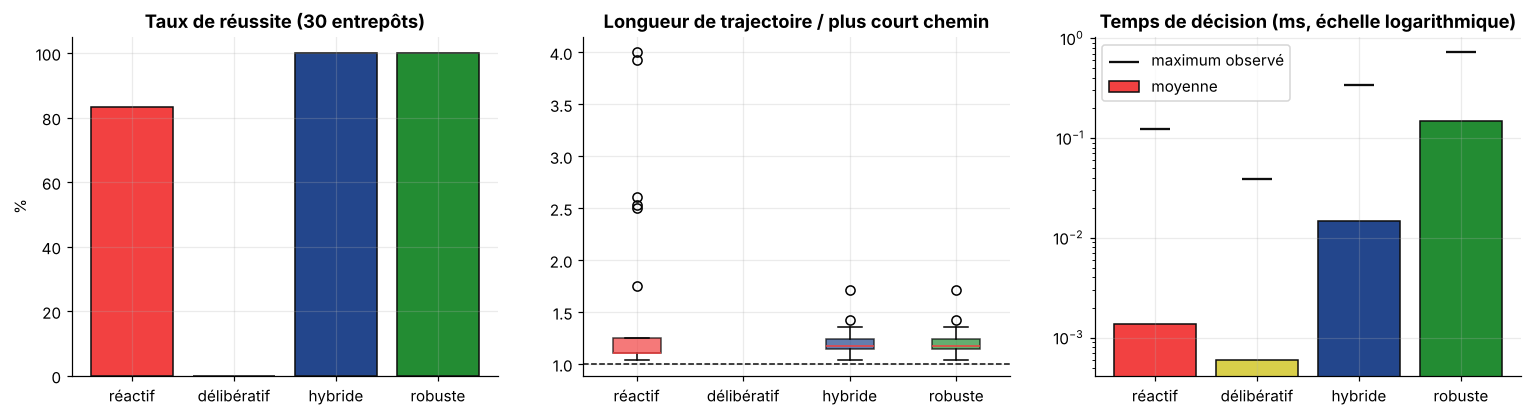

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
couleurs = [ROUGE, JAUNE, BLEU, VERT]
axes[0].bar(synthese.index, synthese["succès (%)"], color=couleurs, edgecolor=NOIR)
axes[0].set_title("Taux de réussite (30 entrepôts)")
axes[0].set_ylabel("%")
boites = axes[1].boxplot([fine[(fine["agent"] == a) & fine["succès"]]["allongement"] for a in AGENTS], patch_artist=True)
axes[1].set_xticks(range(1, len(AGENTS) + 1), list(AGENTS))
for b, c in zip(boites["boxes"], couleurs):
    b.set_facecolor(c)
    b.set_alpha(0.7)
axes[1].axhline(1, color=NOIR, ls="--", lw=1)
axes[1].set_title("Longueur de trajectoire / plus court chemin")
axes[2].bar(synthese.index, synthese["décision moyenne (ms)"], color=couleurs, edgecolor=NOIR, label="moyenne")
axes[2].scatter(synthese.index, synthese["décision max (ms)"], color=NOIR, marker="_", s=400, label="maximum observé", zorder=5)
axes[2].set_yscale("log")
axes[2].set_title("Temps de décision (ms, échelle logarithmique)")
axes[2].legend()
plt.show()

Le temps de décision se valide comme le reste : en robotique, c'est le **pire cas** qui compte, car la décision doit tomber avant la fin du cycle de contrôle. Une replanification A* ou une mise à jour de filtre coûtent bien plus que la moyenne.

### Rejouer un échec avec la trace complète

La trace contient, pour chaque étape, l'état, l'observation, la décision et sa justification. On affiche la fin d'une mission échouée.

Échecs par agent : {'délibératif': 30, 'réactif': 5}

Rejeu : agent délibératif, entrepôt 0, 16 collision(s)
  étape   0 robot [1, 1] action S        | Plan A* calculé (144 nœuds explorés), exécution à l'estime
  étape   1 robot [1, 2] action S        | Étape 2 sur 28 du plan initial
  étape   2 robot [1, 3] action E        | Étape 3 sur 28 du plan initial
  étape   3 robot [2, 3] action S        | Étape 4 sur 28 du plan initial
  étape   4 robot [2, 4] action S        | Étape 5 sur 28 du plan initial
  étape   5 robot [2, 5] action S        | Étape 6 sur 28 du plan initial
  étape 116 robot [4, 7] action ATTENDRE | Plan terminé
  étape 117 robot [4, 7] action ATTENDRE | Plan terminé
  étape 118 robot [4, 7] action ATTENDRE | Plan terminé
  étape 119 robot [4, 7] action ATTENDRE | Plan terminé


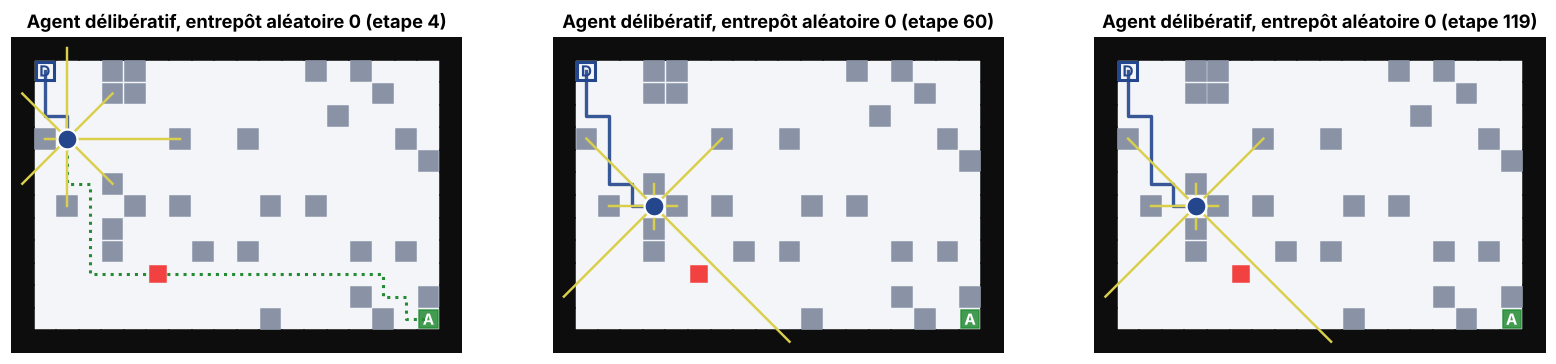

Lecture : l'agent déroule son plan à l'estime. Après un glissement ou un choc contre la palette, il est décalé, se croit arrivé et s'arrête loin de l'objectif.
Trace enregistrée pour le rejeu dans la scène 3D : resultats/m6-echec.json


In [19]:
echecs = fine[~fine["succès"]]
print("Échecs par agent :", echecs.groupby("agent").size().to_dict())
cible = echecs[echecs["agent"].isin(["hybride", "robuste"])]
ligne = (cible if len(cible) else echecs).iloc[0]
trace = traces[ligne["agent"], ligne["entrepôt"]]
print(f"\nRejeu : agent {ligne['agent']}, entrepôt {ligne['entrepôt']}, {trace.bilan['collisions']} collision(s)")
for e in trace.etapes[:6] + trace.etapes[-4:]:
    print(f"  étape {e['t']:3d} robot {e['etat']['robot']} action {e['action']:8s} | {e['decision'].get('raison', '')}")
fig, axes = plt.subplots(1, 3, figsize=(18, 4.4))
for ax, t in zip(axes, (4, len(trace.etapes) // 2, len(trace.etapes) - 1)):
    dessiner_trace(trace, t, ax)
    ax.get_legend().remove()
plt.show()
if ligne["agent"] == "délibératif":
    print("Lecture : l'agent déroule son plan à l'estime. Après un glissement ou un choc contre la palette, il est décalé, se croit arrivé et s'arrête loin de l'objectif.")
elif ligne["agent"] == "réactif":
    print("Lecture : sans carte ni mémoire, l'agent tourne en rond dans un cul-de-sac formé par les rayonnages.")
chemin = trace.enregistrer(RESULTATS / "m6-echec.json")
print(f"Trace enregistrée pour le rejeu dans la scène 3D : {chemin}")

### Exercice 4. Durcir la campagne fine

Modifiez les paramètres de la campagne fine (densité des rayonnages, glissement, bruit du lidar) et relancez les deux cellules précédentes. Quel agent se dégrade le plus vite ? La cellule ci-dessous compare rapidement deux densités pour l'agent réactif (remplacez `AgentReactif` par un autre agent pour comparer).

In [20]:
# À VOUS : choisissez les densités à comparer.
DENSITES = [0.10, 0.22]

for densite in DENSITES:
    bilans = []
    for graine in range(20):
        m = entrepot_aleatoire(graine, densite=densite, glissement=0.1, bruit_lidar=0.3)
        bilans.append(simuler(m, AgentReactif(), max_etapes=120).bilan)
    print(f"densité {densite:.2f} : succès {100 * np.mean([b['succes'] for b in bilans]):.0f} %, étapes médianes {np.median([b['etapes'] for b in bilans]):.0f}, "
          f"décision max {max(b['temps_decision_max_ms'] for b in bilans):.2f} ms")

densité 0.10 : succès 85 %, étapes médianes 32, décision max 0.07 ms


densité 0.22 : succès 55 %, étapes médianes 86, décision max 0.02 ms


**Solution possible.** On balaie la densité pour les quatre agents.

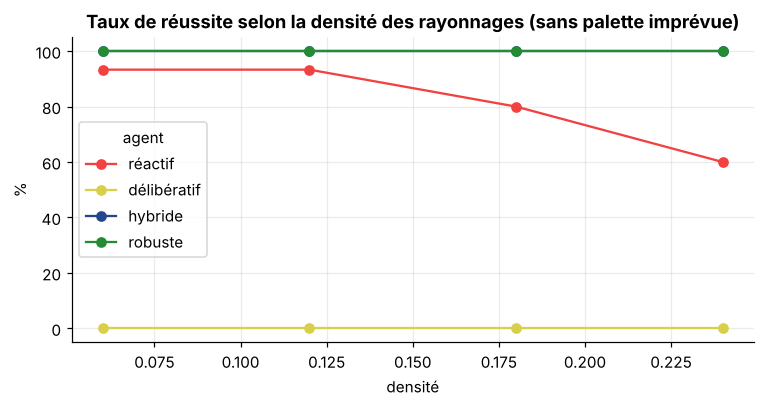

L'agent réactif se dégrade le premier : plus la carte est encombrée, plus il rencontre de culs-de-sac.
L'agent délibératif, en boucle ouverte, est sensible au glissement quelle que soit la densité.


agent,réactif,délibératif,hybride,robuste
densité,,,,
0.06,93.0,0.0,100.0,100.0
0.12,93.0,0.0,100.0,100.0
0.18,80.0,0.0,100.0,100.0
0.24,60.0,0.0,100.0,100.0


In [21]:
lignes = []
for densite in (0.06, 0.12, 0.18, 0.24):
    for nom, fabrique in AGENTS.items():
        bilans = [simuler(entrepot_aleatoire(g, densite=densite, glissement=0.1, bruit_lidar=0.3), fabrique(), max_etapes=120).bilan for g in range(15)]
        lignes.append({"densité": densite, "agent": nom, "succès (%)": 100 * np.mean([b["succes"] for b in bilans])})
balayage = pd.DataFrame(lignes).pivot(index="densité", columns="agent", values="succès (%)")[list(AGENTS)]
balayage.plot(marker="o", color=couleurs, figsize=(8, 3.6), title="Taux de réussite selon la densité des rayonnages (sans palette imprévue)", ylabel="%")
plt.show()
print("L'agent réactif se dégrade le premier : plus la carte est encombrée, plus il rencontre de culs-de-sac.")
print("L'agent délibératif, en boucle ouverte, est sensible au glissement quelle que soit la densité.")
balayage.round(0)

## Partie 7. Rapport de validation et bonnes pratiques

Une campagne qui ne laisse pas de trace écrite n'a pas eu lieu. Le rapport de validation rassemble ce qu'il faut pour **reproduire** et **décider** : version du système, configuration, graines, niveaux testés, indicateurs avec leur incertitude, verdicts, échecs analysés et limites connues. La cellule suivante le génère automatiquement à partir des résultats du notebook.

In [22]:
def tableau_markdown(df):
    """Convertit un DataFrame en tableau Markdown, sans dépendance supplémentaire."""
    lignes = ["| " + " | ".join(str(c) for c in df.columns) + " |", "|" + "---|" * len(df.columns)]
    for _, r in df.iterrows():
        lignes.append("| " + " | ".join(f"{v:.3f}" if isinstance(v, float) else str(v) for v in r) + " |")
    return "\n".join(lignes)


apres = verdicts[verdicts["version"] == "après correction"]
decision = "ACCEPTÉ dans les domaines nominal et dégradé" if (apres["verdict"] != "NON CONFORME").all() else "REFUSÉ : au moins une exigence n'est pas tenue"
colonnes = ["niveau", "domaine", "version", "succès", "IC bas", "IC haut", "mission sûre", "collisions", "étapes (médiane)", "étapes (p95)"]
rapport = f"""# Rapport de validation : navigation autonome en entrepôt simulé

Formation ASCENT 4-130, module 6. Rapport généré automatiquement par le notebook `06_tests_validation`.

## 1. Identification

- Date : {date.today().isoformat()}
- Système testé : politique de descente du champ de distance, avec et sans évitement des obstacles perçus
- Bibliothèque : ascent_agents {ascent_agents.__version__}, PyTorch {torch.__version__}, Python {platform.python_version()}
- Appareil de calcul : {APPAREIL}
- Graine : {GRAINE} (campagne reproductible)

## 2. Plan de test

- Carte : entrepôt de référence, 20 × 14 cellules, plus court chemin de 26 pas
- Échéance de mission : {PARAMETRES_CAMPAGNE['max_etapes']} étapes
- Missions par niveau et par version : {PARAMETRES_CAMPAGNE['lot']}

{tableau_markdown(pd.DataFrame(NIVEAUX))}

Critères d'acceptation (comparés à la borne basse de l'intervalle de confiance à 95 %) :

{tableau_markdown(pd.DataFrame([dict(domaine=d, **{k: v for k, v in s.items()}) for d, s in SEUILS.items() if s]))}

## 3. Résultats de la campagne par lots

{tableau_markdown(campagne[colonnes].round(3))}

## 4. Verdicts

{tableau_markdown(verdicts)}

**Décision pour la version corrigée : {decision}.**

## 5. Campagne fine sur {PARAMETRES_FINE['entrepots']} entrepôts aléatoires

Conditions : densité {PARAMETRES_FINE['densite']}, glissement {PARAMETRES_FINE['glissement']}, bruit du lidar {PARAMETRES_FINE['bruit_lidar']}, palette imprévue sur le plus court chemin.

{tableau_markdown(synthese.round(3).reset_index())}

## 6. Échecs analysés

- Campagne par lots, niveau dégradé, mission n° {cas} : {brut['collisions'][cas]} collision(s). Cause : obstacle mobile voisin non perçu, le robot avance sur la cellule occupée.
- Campagne fine : agent {ligne['agent']}, entrepôt aléatoire {ligne['entrepôt']}. Trace conservée dans `resultats/m6-echec.json`.

## 7. Limites de cette validation

- Résultats obtenus en simulation uniquement : aucun essai sur robot réel.
- Monde discret (grille), obstacles mobiles à marche aléatoire, bruits indépendants d'une étape à l'autre. Un capteur réel présente des erreurs corrélées dans le temps.
- Une seule carte pour la campagne par lots. La campagne fine couvre {PARAMETRES_FINE['entrepots']} cartes, ce qui donne des intervalles de confiance larges.
- Le niveau « limite » n'a pas de critère d'acceptation : le système ne doit pas être exploité dans ces conditions.
"""
(RESULTATS / "rapport_validation.md").write_text(rapport, encoding="utf-8")
donnees = {
    "date": date.today().isoformat(), "graine": GRAINE, "appareil": str(APPAREIL), "campagne": PARAMETRES_CAMPAGNE, "niveaux": NIVEAUX, "seuils": SEUILS,
    "resultats": campagne.round(4).to_dict(orient="records"), "verdicts": verdicts.to_dict(orient="records"),
    "campagne_fine": {"parametres": PARAMETRES_FINE, "synthese": synthese.round(4).reset_index().to_dict(orient="records")},
    "decision": decision,
}
(RESULTATS / "rapport_validation.json").write_text(json.dumps(donnees, ensure_ascii=False, indent=1), encoding="utf-8")
print(f"Rapport écrit : {RESULTATS / 'rapport_validation.md'} ({len(rapport.splitlines())} lignes) et {RESULTATS / 'rapport_validation.json'}")
print("\n".join(rapport.splitlines()[:16]))

Rapport écrit : resultats/rapport_validation.md (87 lignes) et resultats/rapport_validation.json
# Rapport de validation : navigation autonome en entrepôt simulé

Formation ASCENT 4-130, module 6. Rapport généré automatiquement par le notebook `06_tests_validation`.

## 1. Identification

- Date : 2026-11-14
- Système testé : politique de descente du champ de distance, avec et sans évitement des obstacles perçus
- Bibliothèque : ascent_agents 1.0.0, PyTorch 2.15.0+cpu, Python 3.13.18
- Appareil de calcul : cpu
- Graine : 4130 (campagne reproductible)

## 2. Plan de test

- Carte : entrepôt de référence, 20 × 14 cellules, plus court chemin de 26 pas
- Échéance de mission : 45 étapes


### De la simulation au déploiement réel : bonnes pratiques

**L'écart entre simulation et réalité.** Un simulateur simplifie : monde discret, bruits indépendants, obstacles au comportement stylisé. Un résultat de simulation est une condition nécessaire, pas une preuve de bon fonctionnement sur site.
- Mesurer les bruits réels des capteurs et recaler le simulateur dessus.
- Faire varier les paramètres du simulateur autour des valeurs mesurées, pour ne pas valider un agent ajusté à un seul réglage.
- Prévoir une montée en charge progressive : simulation, banc d'essai, zone fermée, exploitation supervisée, exploitation normale.

**Journalisation.** Chaque exécution, en test comme en exploitation, doit laisser une trace exploitable : observations, décision, justification, action, résultat, horodatage, version du logiciel et configuration. C'est le format de trace utilisé dans toute cette formation. Sans journal, un incident ne peut ni être rejoué ni être expliqué.

**Critères d'arrêt et surveillance.** Un agent autonome doit connaître les limites de son domaine validé.
- Définir le domaine d'emploi (ici : jusqu'au niveau « sévère ») et surveiller en service les grandeurs qui le délimitent (taux de glissement observé, densité de trafic).
- Prévoir un comportement de repli sûr (arrêt, demande d'aide à un opérateur) quand le doute est trop grand, par exemple quand l'entropie de la croyance dépasse un seuil (module 5).
- Fixer des critères d'arrêt de l'exploitation : nombre de collisions, de missions manquées ou de replis sur une période.

**Documentation.** Conserver avec chaque version : le plan de test, les seuils et leur justification, le rapport de validation, les échecs connus et les limites. Toute modification du système relance la campagne de non-régression.

## Synthèse du module

- Valider un agent autonome, c'est le soumettre à une grille de scénarios (nominal, dégradé, limite) avec des critères d'acceptation fixés avant la campagne.
- Un seul indicateur ne suffit pas : le taux de réussite peut rester élevé alors que les collisions se multiplient. On suit aussi les distributions et les pires cas.
- Un taux mesuré est une estimation. L'intervalle de confiance de Wilson en donne la précision, qui s'améliore comme 1 / √n : c'est ce qui justifie la simulation par lots, accélérée sur GPU.
- Une campagne reproductible (graines fixées) permet la non-régression automatique et le rejeu des échecs, étape par étape, à partir des traces.
- La simulation ne remplace pas l'essai réel. Le rapport de validation documente les conditions testées, les résultats, les échecs analysés et les limites du domaine d'emploi.

## Auto-évaluation

Sans relire le notebook, cochez ce que vous sauriez refaire seul sur un nouveau problème :

- [ ] Je sais concevoir une grille de scénarios de test, du nominal aux limites.
- [ ] Je sais lancer une campagne de simulations et présenter un taux de réussite avec son intervalle de confiance.
- [ ] Je sais rejouer un échec à partir de sa graine et de sa trace.
- [ ] Je sais rédiger un rapport de validation avec des seuils d'acceptation.

Pour chaque case que vous hésitez à cocher, reprenez la partie correspondante et refaites son exercice sans regarder la solution. Les trois questions de la section « Vérifiez vos acquis » du module, sur le site, complètent ce bilan.